# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** The objective is to predict whether a breast mass is malignant or benign based on 30 numeric features derived from cell nucleus measurements in fine-needle aspirate (FNA) images. This is a supervised binary classification problem evaluated using 569 patient instances. A false negative (classifying a malignant mass as benign) is significantly more costly than a false positive because a missed cancer diagnosis delays critical medical treatment and lowers patient survival outcomes. Success will be judged primarily by achieving a high recall (sensitivity) score for the malignant class while maintaining strong overall classification accuracy and ROC-AUC during stratified cross-validation.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier,
                              VotingClassifier)

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [4]:
# TODO: load the dataset and copy its DataFrame into df
data = load_breast_cancer(as_frame=True)
df = data.frame
print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [5]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
print("Shape:", df.shape)
print("\nData type counts:\n", df.dtypes.value_counts())
display(df.head())

Shape: (569, 31)

Data type counts:
 float64    30
int64       1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [6]:
# TODO: class counts and percentages
print("Class counts:")
print(df['target'].value_counts())
print("\nClass proportions:")
print(df['target'].value_counts(normalize=True))

Class counts:
target
1    357
0    212
Name: count, dtype: int64

Class proportions:
target
1    0.627417
0    0.372583
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [7]:
# TODO: describe().T, then the 10 largest skewness values
summary_stats = df.describe().T
display(summary_stats)
skewness = df.drop(columns=['target']).skew().abs()
top_10_skewed = skewness.sort_values(ascending=False).head(10)

print("\n10 Most Skewed Features (absolute skewness):")
print(top_10_skewed)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



10 Most Skewed Features (absolute skewness):
area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [8]:
# TODO: correlation with target, sorted
correlations = df.corr()['target'].drop('target')
print("5 Most Negative Correlations:")
print(correlations.sort_values().head(5))
print("\n5 Most Positive Correlations:")
print(correlations.sort_values(ascending=False).head(5))

5 Most Negative Correlations:
worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64

5 Most Positive Correlations:
smoothness error           0.067016
mean fractal dimension     0.012838
texture error              0.008303
symmetry error             0.006522
fractal dimension error   -0.077972
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** Features like area error and concavity error have high skewness (heavy right tails). Normalizing or scaling these skewed distributions is crucial so extreme values do not distort distance- and linear-based models like KNN, SVM, and Logistic Regression.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

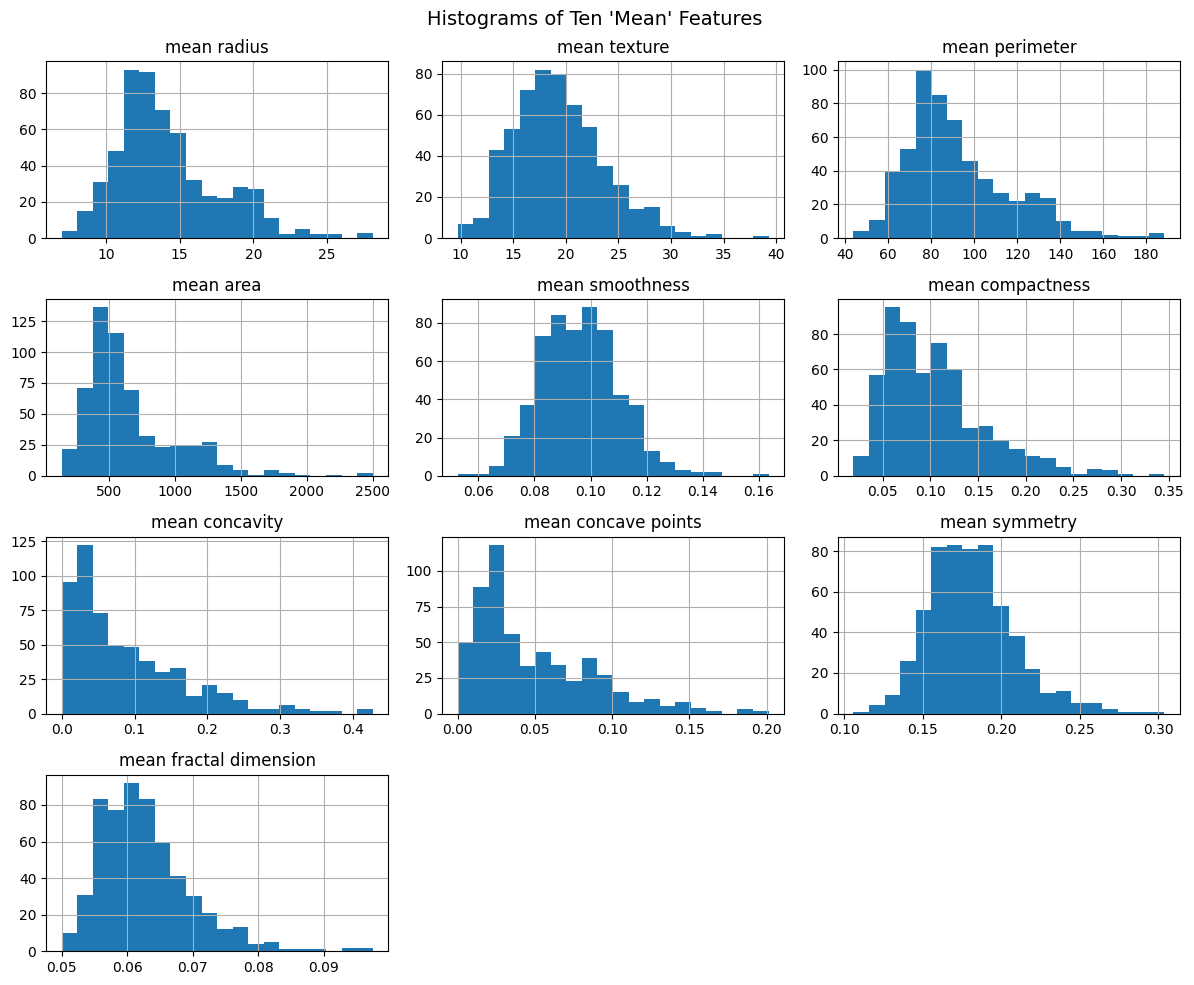

In [9]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
df.filter(like="mean").hist(bins=20, figsize=(12, 10), layout=(4, 3), grid=True)
plt.suptitle("Histograms of Ten 'Mean' Features", fontsize=14)
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

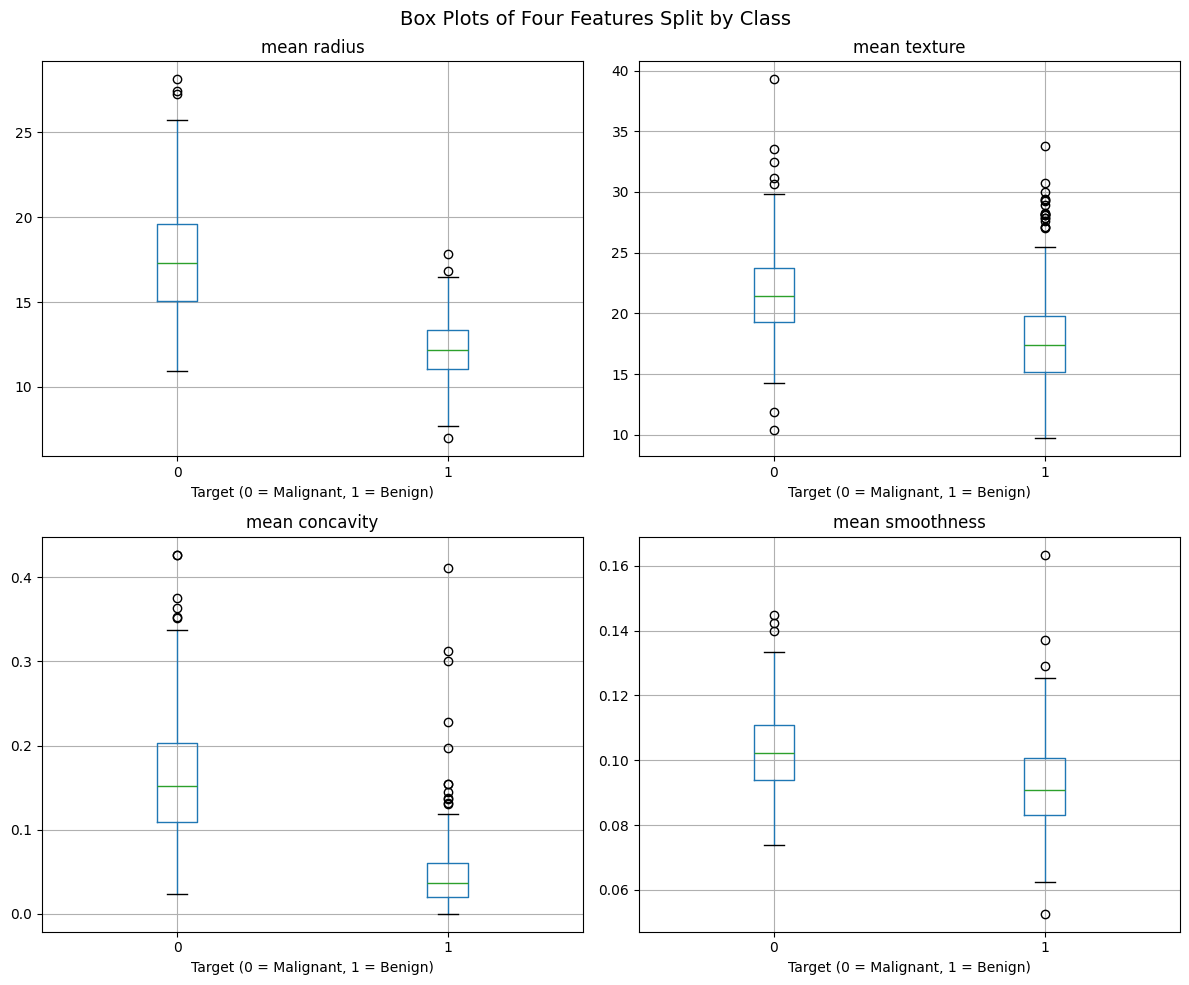

In [10]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

# Create 2x2 box plots grouped by target class
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    df.boxplot(column=col, by="target", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("Target (0 = Malignant, 1 = Benign)")

plt.suptitle("Box Plots of Four Features Split by Class", fontsize=14)
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

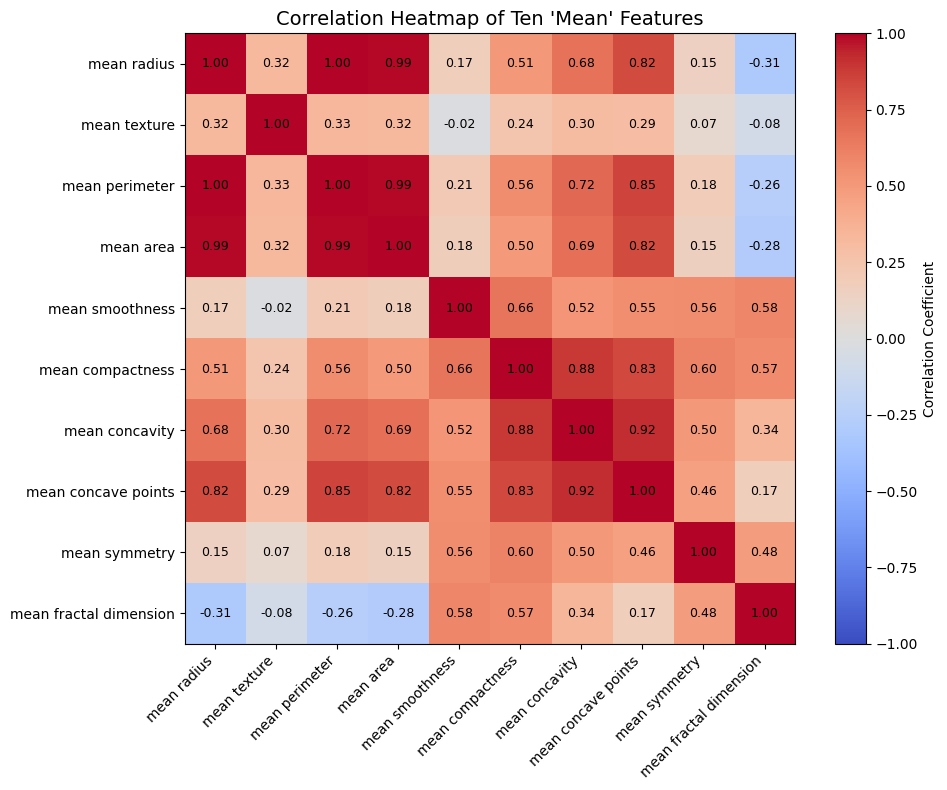

In [11]:
# TODO: correlation matrix of the "mean" features drawn with imshow
mean_df = df.filter(like="mean")

corr = mean_df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Correlation Coefficient")

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        text = ax.text(j, i, f"{corr.iloc[i, j]:.2f}",
                       ha="center", va="center", color="black", fontsize=9)

plt.title("Correlation Heatmap of Ten 'Mean' Features", fontsize=14)
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

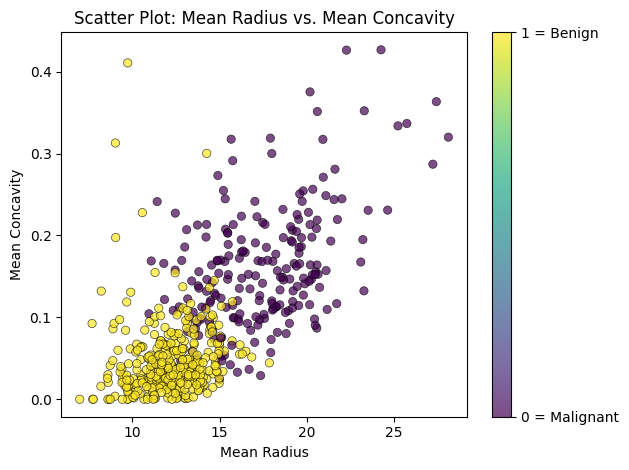

In [12]:
# TODO: coloured scatter plot with axis labels and a colourbar

scatter = plt.scatter(
    df['mean radius'],
    df['mean concavity'],
    c=df['target'],
    cmap='viridis',
    alpha=0.7,
    edgecolors='k',
    linewidths=0.5
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Scatter Plot: Mean Radius vs. Mean Concavity")

cbar = plt.colorbar(scatter)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(['0 = Malignant', '1 = Benign'])

plt.tight_layout()
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** Mean radius, mean perimeter, and mean area are redundant because they measure the same physical size (correlation near 1.0). The same goes for mean compactness, mean concavity, and mean concave points.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [13]:
# TODO: total missing values and duplicated rows
print("Total duplicate rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]

Total duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [14]:
# TODO: IQR outlier count per feature

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outliers = (X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))

outlier_counts = outliers.sum().sort_values(ascending=False).head(10)

print("Top 10 features with the most outliers (IQR rule):")
print(outlier_counts)

Top 10 features with the most outliers (IQR rule):
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** *No, I would not delete the outlying rows.In clinical diagnostic datasets like breast cancer, extreme feature values (e.g., unusually large tumor radius or high concavity) represent real, severe malignant cases rather than data collection errors or noise.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [15]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95

corr_matrix = X.corr().abs()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]

print("Features with absolute correlation > 0.95 with an earlier feature:")
print(to_drop)

Features with absolute correlation > 0.95 with an earlier feature:
['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [16]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

kbest_scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)

kbest_features = kbest_scores.head(10).index.tolist()

print("Top 10 features selected by SelectKBest(f_classif):")
print(kbest_scores.head(10))

Top 10 features selected by SelectKBest(f_classif):
worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [17]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

estimator = LogisticRegression(max_iter=1000, random_state=7)
rfe = RFE(estimator, n_features_to_select=10)
rfe.fit(X_scaled, y)

rfe_features = X.columns[rfe.support_].tolist()

print("Top 10 features selected by RFE:")
print(rfe_features)

Top 10 features selected by RFE:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

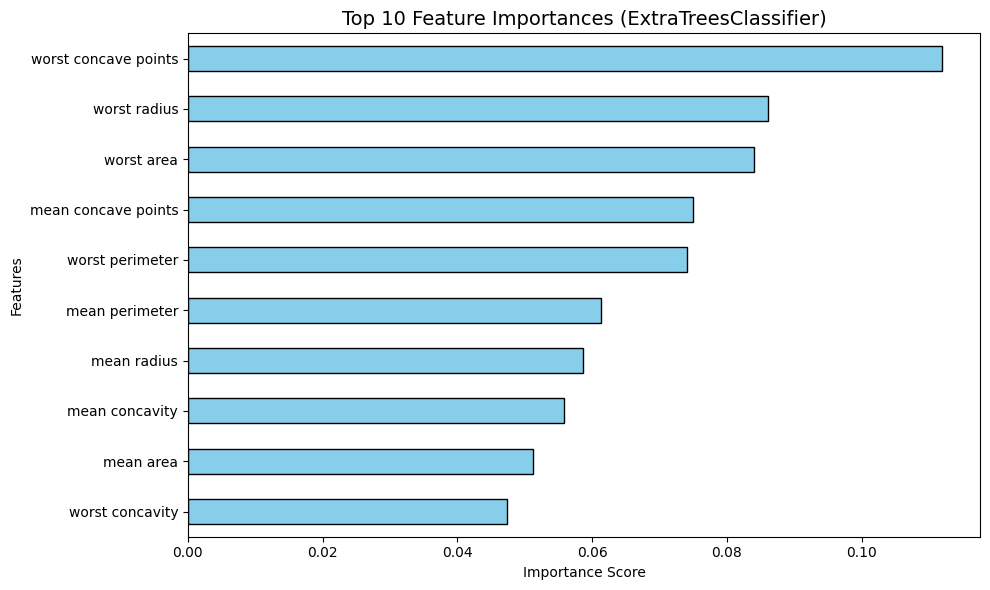

In [18]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
et_model = ExtraTreesClassifier(n_estimators=200, random_state=7)
et_model.fit(X, y)

imp = pd.Series(et_model.feature_importances_, index=X.columns).sort_values(ascending=True)
top_10_imp = imp.tail(10)

plt.figure(figsize=(10, 6))
top_10_imp.plot(kind='barh', color='skyblue', edgecolor='black')
plt.title("Top 10 Feature Importances (ExtraTreesClassifier)", fontsize=14)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [19]:
# TODO: vote across the three methods
et_features = top_10_imp.index.tolist()

from collections import Counter

all_votes = kbest_features + rfe_features + et_features
vote_counts = Counter(all_votes)

selected = [feature for feature, count in vote_counts.items() if count >= 2]

print(f"Number of selected features: {len(selected)}")
print("Selected features:", selected)

Number of selected features: 10
Selected features: ['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter', 'worst area', 'mean radius', 'mean area', 'mean concavity', 'worst concavity']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [20]:
# TODO: train_test_split with stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=7
)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [21]:
# TODO: fit both scalers on X_train and print the verifying statistics
std_scaler = StandardScaler().fit(X_train)
minmax_scaler = MinMaxScaler().fit(X_train)

X_train_std = std_scaler.transform(X_train)
X_train_minmax = minmax_scaler.transform(X_train)

first_four_features = X.columns[:4]

print("StandardScaler - First 4 Features:")
print("Mean:", X_train_std[:, :4].mean(axis=0).round(4))
print("Std: ", X_train_std[:, :4].std(axis=0).round(4))

print("\n" + "="*40 + "\n")

print("MinMaxScaler - First 4 Features:")
print("Min: ", X_train_minmax[:, :4].min(axis=0).round(4))
print("Max: ", X_train_minmax[:, :4].max(axis=0).round(4))

StandardScaler - First 4 Features:
Mean: [ 0. -0. -0. -0.]
Std:  [1. 1. 1. 1.]


MinMaxScaler - First 4 Features:
Min:  [0. 0. 0. 0.]
Max:  [1. 1. 1. 1.]


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [22]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

pca = PCA().fit(X_train_scaled)

cum_variance = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cum_variance >= 0.95) + 1

print(f"Number of components retaining 95% variance: {n_components_95}")

Number of components retaining 95% variance: 10


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [24]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
models = {
    "LR": LogisticRegression(max_iter=1000, random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed)
}


def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [25]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

models = {
    "LR": LogisticRegression(max_iter=1000, random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed)
}


def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** KNN, SVM, Logistic Regression, and LDA benefit significantly from feature scaling.

KNN & SVM: Distance-based models. Large-scale features (like tumor area) overpower small-scale features (like smoothness) unless scaled equally.

Logistic Regression & LDA: Optimization-based models. Scaling creates a balanced loss surface, helping solvers converge much faster.

Decision Trees (CART): Scale-invariant. They split one feature at a time based on relative thresholds, so scaling changes nothing.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [29]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
results_scaled = spot_check(models, X_train, scale=True)

results_selected = spot_check(models, X_train[selected], scale=True)

summary_comparison = pd.DataFrame({
    "all_scaled": {name: scores.mean() for name, scores in results_scaled.items()},
    "selected_scaled": {name: scores.mean() for name, scores in results_selected.items()}
})

print("Mean CV Accuracy Comparison (All Scaled vs. Selected Scaled):")
display(summary_comparison)

Mean CV Accuracy Comparison (All Scaled vs. Selected Scaled):


,all_scaled,selected_scaled
LR,0.982319,0.960435
LDA,0.947246,0.942995
KNN,0.964928,0.942802
CART,0.927633,0.925266
NB,0.932029,0.951691
SVM,0.975797,0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

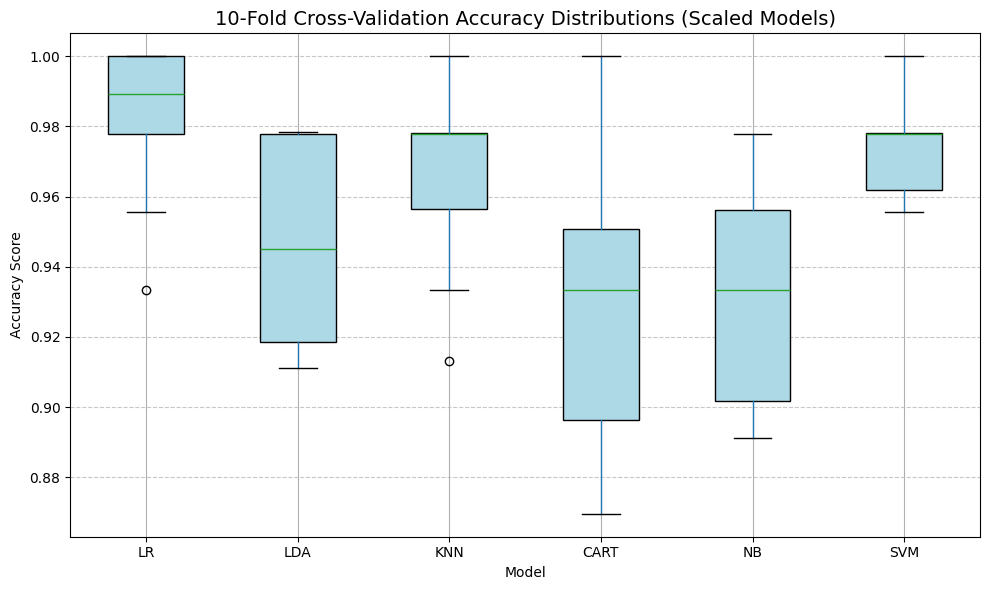

In [30]:
# TODO: box plot of the 10 fold scores per model
df_results = pd.DataFrame(results_scaled)

plt.figure(figsize=(10, 6))
df_results.boxplot(patch_artist=True, boxprops=dict(facecolor='lightblue'))

plt.title("10-Fold Cross-Validation Accuracy Distributions (Scaled Models)", fontsize=14)
plt.ylabel("Accuracy Score")
plt.xlabel("Model")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [31]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
scoring = {
    'accuracy': 'accuracy',
    'roc_auc': 'roc_auc',
    'recall_malignant': make_scorer(recall_score, pos_label=0)
}

best_model_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=seed))
])

cv_results = cross_validate(best_model_pipeline, X_train, y_train, cv=kfold, scoring=scoring)

print(f"Mean Accuracy:           {cv_results['test_accuracy'].mean():.4f}")
print(f"Mean ROC-AUC:            {cv_results['test_roc_auc'].mean():.4f}")
print(f"Mean Malignant Recall:   {cv_results['test_recall_malignant'].mean():.4f}")

Mean Accuracy:           0.9823
Mean ROC-AUC:            0.9922
Mean Malignant Recall:   0.9647


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [32]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
pipe_svm = Pipeline([
    ('scale', StandardScaler()),
    ('model', SVC(random_state=seed))
])

param_grid_svm = {
    'model__C': [0.1, 1, 10, 100],
    'model__gamma': ['scale', 0.001, 0.01, 0.1],
    'model__kernel': ['rbf', 'linear']
}

grid_svm = GridSearchCV(
    estimator=pipe_svm,
    param_grid=param_grid_svm,
    scoring='accuracy',
    cv=kfold,
    n_jobs=-1
)
grid_svm.fit(X_train, y_train)

print("Best SVM Parameters:", grid_svm.best_params_)
print(f"Best 10-Fold CV Accuracy: {grid_svm.best_score_:.4f}")

Best SVM Parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best 10-Fold CV Accuracy: 0.9802


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [33]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
pipe_knn = Pipeline([
    ('scale', StandardScaler()),
    ('model', KNeighborsClassifier())
])

param_grid_knn = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'model__weights': ['uniform', 'distance']
}

grid_knn = GridSearchCV(
    estimator=pipe_knn,
    param_grid=param_grid_knn,
    scoring='accuracy',
    cv=kfold,
    n_jobs=-1
)
grid_knn.fit(X_train, y_train)

print("Best KNN Parameters:", grid_knn.best_params_)
print(f"Best 10-Fold CV Accuracy: {grid_knn.best_score_:.4f}")

Best KNN Parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best 10-Fold CV Accuracy: 0.9693


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [34]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
tuned_svm = Pipeline([
    ('scale', StandardScaler()),
    ('model', SVC(C=0.1, kernel='linear', random_state=seed))
])

tuned_knn = Pipeline([
    ('scale', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=3, weights='uniform'))
])

rf_model = RandomForestClassifier(random_state=seed)

voting_model = VotingClassifier(
    estimators=[
        ('svm', tuned_svm),
        ('knn', tuned_knn),
        ('rf', rf_model)
    ],
    voting='hard'
)

ensembles = {
    "RF": rf_model,
    "ET": ExtraTreesClassifier(random_state=seed),
    "GBM": GradientBoostingClassifier(random_state=seed),
    "AB": AdaBoostClassifier(random_state=seed),
    "Voting": voting_model
}

results_ensembles = spot_check(ensembles, X_train, scale=False)

summary_ensembles = pd.Series(
    {name: scores.mean() for name, scores in results_ensembles.items()}
)
print("Ensemble Methods Mean CV Accuracy:")
print(summary_ensembles.round(4))

Ensemble Methods Mean CV Accuracy:
RF        0.9691
ET        0.9736
GBM       0.9670
AB        0.9626
Voting    0.9781
dtype: float64


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [35]:
# TODO: leaderboard Series
leaderboard_data = {
    "Tuned SVM": grid_svm.best_score_,
    "Tuned KNN": grid_knn.best_score_,
    "Random Forest": summary_ensembles["RF"],
    "Extra Trees": summary_ensembles["ET"],
    "Gradient Boosting": summary_ensembles["GBM"],
    "AdaBoost": summary_ensembles["AB"],
    "Voting Classifier": summary_ensembles["Voting"]
}

leaderboard = pd.Series(leaderboard_data).sort_values(ascending=False)

print("Leaderboard (Mean CV Accuracy):")
print(leaderboard.round(4))

Leaderboard (Mean CV Accuracy):
Tuned SVM            0.9802
Voting Classifier    0.9781
Extra Trees          0.9736
Tuned KNN            0.9693
Random Forest        0.9691
Gradient Boosting    0.9670
AdaBoost             0.9626
dtype: float64


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Test Set Accuracy: 0.9649

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



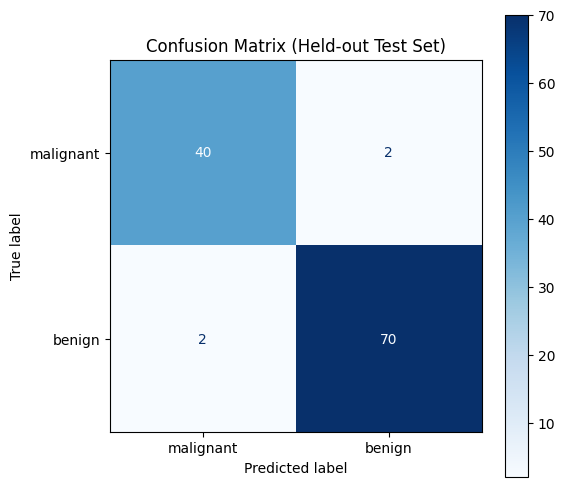

In [36]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
best_model = grid_svm.best_estimator_

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
print(f"Test Set Accuracy: {test_acc:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=data.target_names, cmap="Blues", ax=ax
)
plt.title("Confusion Matrix (Held-out Test Set)")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [37]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
import joblib

filename = "best_svm_model.joblib"
joblib.dump(best_model, filename)

loaded_model = joblib.load(filename)

loaded_preds = loaded_model.predict(X_test)

print("First 5 Original Predictions:", y_pred[:5])
print("First 5 Reloaded Predictions:", loaded_preds[:5])
print("First 5 Actual Labels (y_test):", y_test.iloc[:5].values)

print("Do predictions match exactly?", np.array_equal(y_pred, loaded_preds))

First 5 Original Predictions: [0 0 1 0 1]
First 5 Reloaded Predictions: [0 0 1 0 1]
First 5 Actual Labels (y_test): [0 0 1 0 1]
Do predictions match exactly? True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.

**Answer:** Selecting features using the whole dataset allows information from the validation folds to leak into the training process. This gives the model an unfair preview of the test data, resulting in overly optimistic cross-validation scores that won't hold up in real-world deployment. To fix this, you must place the feature selection step (such as SelectKBest) directly inside a scikit-learn Pipeline. This ensures feature selection is fitted strictly on the training folds during each cross-validation split without seeing the validation fold.

2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?

**Answer:** I would report Recall (Sensitivity) for the malignant class alongside the ROC-AUC score to a clinician. Accuracy alone is insufficient because, in a medical context, predicting a malignant mass as benign (a false negative) is far more dangerous than a false positive. High accuracy can easily hide a high rate of missed cancers if the dataset has more benign cases. Tracking recall ensures we minimize missed diagnoses, while ROC-AUC evaluates how well the model separates the two classes across different probability thresholds.

3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)

**Answer:** When two models differ by only 0.3% in cross-validation accuracy, that small difference is usually statistically insignificant noise. I would first check the variance (standard deviation) of the accuracy scores across all 10 folds to see which model is more stable. Next, I would consider model interpretability, as simpler models like Logistic Regression or Decision Trees are easier to explain to healthcare professionals than complex ensembles. Finally, I would factor in training cost, inference speed, and memory usage, ultimately selecting the simpler, faster, and more robust model over a negligible 0.3% gain.

4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?

**Answer:** With a much smaller dataset, cross-validation scores would suffer from high variance, making overestimation or underestimation of model performance far more likely. Severe class imbalance would cause standard accuracy to become misleading, as a dummy model predicting the majority class could achieve high accuracy while completely failing to detect malignant cases. In that scenario, techniques like SMOTE oversampling or class-weight adjustments would become essential during preprocessing. Additionally, stratified sampling would be critical to ensure each fold maintains a representative proportion of the minority class.

5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Answer:** If repeating this workbook with a different dataset (such as an ARFF file), the data loading step changes to use tools like scipy.io.arff or liac-arff instead of sklearn.datasets. You would also need to adjust the data cleaning steps, handling categorical features with one-hot encoding and addressing any missing values via imputation. The target encoding would need to be updated to map whatever class labels exist in the new dataset. However, the core workflow building a leak-free pipeline, spot-checking algorithms, hyperparameter tuning, and evaluating on a held-out test set remains identical.


**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.